### Não determinístico

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from agentes import QLearning, Sarsa, criar_env, avaliar

CHUVA = dict(is_rainy=True, rainy_probability=0.6)

As classes `QLearning` e `Sarsa` ficam no arquivo [`agentes.py`](agentes.py), usado pelos dois notebooks. Cada execução usa uma seed diferente (`seed=run`), então rodar o notebook de novo gera exatamente os mesmos resultados.

In [2]:
os.makedirs('data_qlearning_rainy', exist_ok=True)
os.makedirs('results_qlearning_rainy', exist_ok=True)

N_RUNS, EPISODES, TARGET = 5, 20_000, 8
all_rewards, all_timesteps = [], []

for run in range(N_RUNS):
    env = criar_env(**CHUVA)
    qlearning = QLearning(env, alpha=0.1, gamma=0.99,
                          epsilon=0.7, epsilon_min=0.05, epsilon_dec=0.99,
                          episodes=EPISODES, seed=run)

    qlearning.train(
        filename     = f'data_qlearning_rainy/q-table-taxi-driver-qlearning-run{run+1}.csv',
        plotFile     = f'results_qlearning_rainy/actions_qlearning_run{run+1}',
        rewardFile   = f'results_qlearning_rainy/rewards_qlearning_run{run+1}',
        timestepFile = f'results_qlearning_rainy/timesteps_qlearning_run{run+1}'
    )

    all_rewards.append(qlearning.rewards_per_episode)
    all_timesteps.append(qlearning.timesteps_per_episode)
    env.close()

print("Timesteps por run (média final, últimos 1000 ep.):")
for i, ts in enumerate(all_timesteps, 1):
    print(f"  run{i}: {np.mean(ts[-1000:]):.2f}")

ql_rewards = np.array(all_rewards)
np.save('results_qlearning_rainy/rewards_qlearning.npy', ql_rewards)

Episódio: 2500/20000 | ε=0.0498 | reward médio (últimos 100): -13.27


Episódio: 5000/20000 | ε=0.0498 | reward médio (últimos 100): -7.60


Episódio: 7500/20000 | ε=0.0498 | reward médio (últimos 100): -10.66


Episódio: 10000/20000 | ε=0.0498 | reward médio (últimos 100): -9.60


Episódio: 12500/20000 | ε=0.0498 | reward médio (últimos 100): -10.20


Episódio: 15000/20000 | ε=0.0498 | reward médio (últimos 100): -9.74


... (31 outputs left out)

Episódio: 15000/20000 | ε=0.0498 | reward médio (últimos 100): -5.62


Episódio: 17500/20000 | ε=0.0498 | reward médio (últimos 100): -9.36


Episódio: 20000/20000 | ε=0.0498 | reward médio (últimos 100): -11.23


Timesteps por run (média final, últimos 1000 ep.):
  run1: 26.55
  run2: 26.92
  run3: 27.88
  run4: 26.85
  run5: 27.88


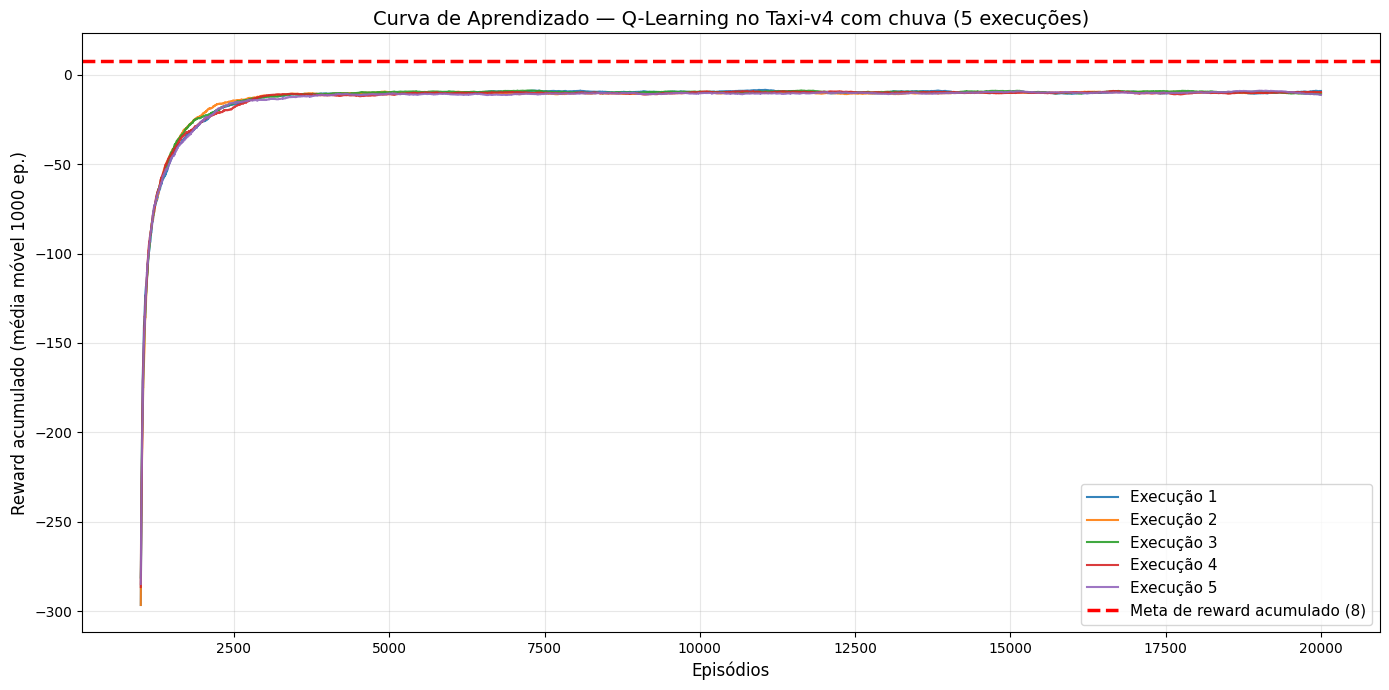

In [3]:
def moving_average(x, window=1000):
    return np.convolve(x, np.ones(window) / window, mode='valid')

plt.figure(figsize=(14, 7))

for i, rewards in enumerate(all_rewards):
    sm = moving_average(np.array(rewards), window=1000)
    plt.plot(np.arange(len(sm)) + 1000, sm,
             linewidth=1.5, alpha=0.9, label=f'Execução {i+1}')

plt.axhline(y=TARGET, color='red', linestyle='--', linewidth=2.5,
            label=f'Meta de reward acumulado ({TARGET})')

plt.xlabel('Episódios', fontsize=12)
plt.ylabel('Reward acumulado (média móvel 1000 ep.)', fontsize=12)
plt.title('Curva de Aprendizado — Q-Learning no Taxi-v4 com chuva (5 execuções)', fontsize=14)
plt.legend(fontsize=11, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('results_qlearning_rainy/learning_curve_5runs.jpg', dpi=120)
plt.show()

### Discussão sobre o QLearning

O aprendizado aconteceu em três fases nas 5 execuções.
1. Início(< 2500 episódios):  o agente não sabe nada e age aleatoriamente. Por isso o reward fica muito negativo.
2. Aprendizado(2500-5000 episódios): o agente para de agir aleatoriamente e começa a agir de forma a usar mais o conhecimento aprendido na Q-table.
3. Estabilidade(>5000 episódios): o agente atinge sua política final e não está mais aprendendo aleatoriamente, não aprendendo mais ativamente ou fazendo melhorias muito pequenas.

#### Por que a curva não chega na meta?

O agente ganha 20 ao entregar o passageiro e perde 1 a cada passo que ele der. Mas, por haver o parâmetro is_rainy=True, o taxi tem uma chance de 40% de não se mover para "onde ele quer" devido aos desvios provocados pela chuva. Portanto, apesar de ele ter aprendido a política, ele tem um reward negativo devido ao fato de ele fazer mais passos que o necessário.

In [4]:
avaliacao_ql_chuva = avaliar('data_qlearning_rainy', 'qlearning', **CHUVA)
avaliacao_ql_chuva

,Execução,Timesteps (média),Desvio padrão,Mín,Máx,Reward médio,Penalidades,Não terminou
0,1,25.95,10.55,9.0,66.0,-4.95,0.0,0.0
1,2,25.82,10.20,9.0,66.0,-4.82,0.0,0.0
2,3,25.43,9.89,9.0,63.0,-4.43,0.0,0.0
3,4,25.40,9.78,9.0,67.0,-4.40,0.0,0.0
4,5,26.11,10.05,11.0,66.0,-5.11,0.0,0.0
Média,Média,25.74,10.09,9.0,67.0,-4.74,0.0,0.0


#### Discussão - Avaliação do agente (Q-Learning com chuva)

Após o treinamento, o agente foi avaliado no ambiente Taxi-v4 com `rainy_probability=0.6`, utilizando a Q-table aprendida, nos mesmos 100 episódios usados no notebook determinístico.

| Execução | Timesteps (média) | Desvio padrão | Mín / Máx | Reward médio | Penalidades | Não terminou |
|---|---|---|---|---|---|---|
| 1 | 25,95 | 10,55 | 9 / 66 | -4,95 | 0 | 0 |
| 2 | 25,82 | 10,20 | 9 / 66 | -4,82 | 0 | 0 |
| 3 | 25,43 | 9,89 | 9 / 63 | -4,43 | 0 | 0 |
| 4 | 25,40 | 9,78 | 9 / 67 | -4,40 | 0 | 0 |
| 5 | 26,11 | 10,05 | 11 / 66 | -5,11 | 0 | 0 |
| **Média** | **25,74** | **10,09** | 9 / 67 | **-4,74** | **0** | **0** |

O agente apresentou uma média de 25,74 passos por episódio, sem registrar penalidades por ações ilegais de pickup ou dropoff e sem nenhum episódio que passou do limite de 200 passos. Isso indica que ele aprendeu a realizar corretamente as operações necessárias para completar a tarefa.

Entretanto, o reward médio ficou em −4,74, não atingindo a meta de ~8. Esse resultado ocorre principalmente devido à chuva, que faz com que o táxi tenha apenas 60% de probabilidade de se mover na direção desejada. Os desvios aumentam a quantidade de movimentos necessários e, como cada passo comum gera uma penalização de −1, a recompensa acumulada pode ficar negativa mesmo quando a entrega é realizada corretamente.

O desvio padrão médio de 10,09 passos não significa necessariamente que o agente seja inconsistente. Essa variação pode ser explicada pelas diferentes posições iniciais do táxi, do passageiro e do destino, além dos movimentos aleatórios provocados pela chuva.

Portanto, **o agente demonstrou ter aprendido a resolver a tarefa sem cometer ações ilegais, mas a aleatoriedade do ambiente aumentou o número de passos e reduziu sua recompensa média**. Apesar de não atingir a meta estabelecida, os resultados mostram um comportamento consistente nas cinco execuções (de 25,40 a 26,11 passos).

### Algoritmo SARSA

In [5]:
os.makedirs('data_sarsa_rainy', exist_ok=True)
os.makedirs('results_sarsa_rainy', exist_ok=True)

N_RUNS, EPISODES, TARGET = 5, 20_000, 8
all_rewards, all_timesteps = [], []

for run in range(N_RUNS):
    env = criar_env(**CHUVA)
    sarsa = Sarsa(env, alpha=0.1, gamma=0.99,
                  epsilon=0.7, epsilon_min=0.05, epsilon_dec=0.99,
                  episodes=EPISODES, seed=run)

    sarsa.train(
        filename     = f'data_sarsa_rainy/q-table-taxi-driver-sarsa-run{run+1}.csv',
        plotFile     = f'results_sarsa_rainy/actions_sarsa_run{run+1}',
        rewardFile   = f'results_sarsa_rainy/rewards_sarsa_run{run+1}',
        timestepFile = f'results_sarsa_rainy/timesteps_sarsa_run{run+1}'
    )

    all_rewards.append(sarsa.rewards_per_episode)
    all_timesteps.append(sarsa.timesteps_per_episode)
    env.close()

print("Timesteps por run (média final, últimos 1000 ep.):")
for i, ts in enumerate(all_timesteps, 1):
    print(f"  run{i}: {np.mean(ts[-1000:]):.2f}")

sarsa_rewards = np.array(all_rewards)
np.save('results_sarsa_rainy/rewards_sarsa.npy', sarsa_rewards)

Episódio: 2500/20000 | ε=0.0498 | reward médio (últimos 100): -17.24


Episódio: 5000/20000 | ε=0.0498 | reward médio (últimos 100): -13.22


Episódio: 7500/20000 | ε=0.0498 | reward médio (últimos 100): -10.62


Episódio: 10000/20000 | ε=0.0498 | reward médio (últimos 100): -9.87


Episódio: 12500/20000 | ε=0.0498 | reward médio (últimos 100): -8.49


Episódio: 15000/20000 | ε=0.0498 | reward médio (últimos 100): -12.18


... (31 outputs left out)

Episódio: 15000/20000 | ε=0.0498 | reward médio (últimos 100): -12.05


Episódio: 17500/20000 | ε=0.0498 | reward médio (últimos 100): -10.84


Episódio: 20000/20000 | ε=0.0498 | reward médio (últimos 100): -11.84


Timesteps por run (média final, últimos 1000 ep.):
  run1: 26.97
  run2: 26.54
  run3: 26.90
  run4: 26.94
  run5: 26.96


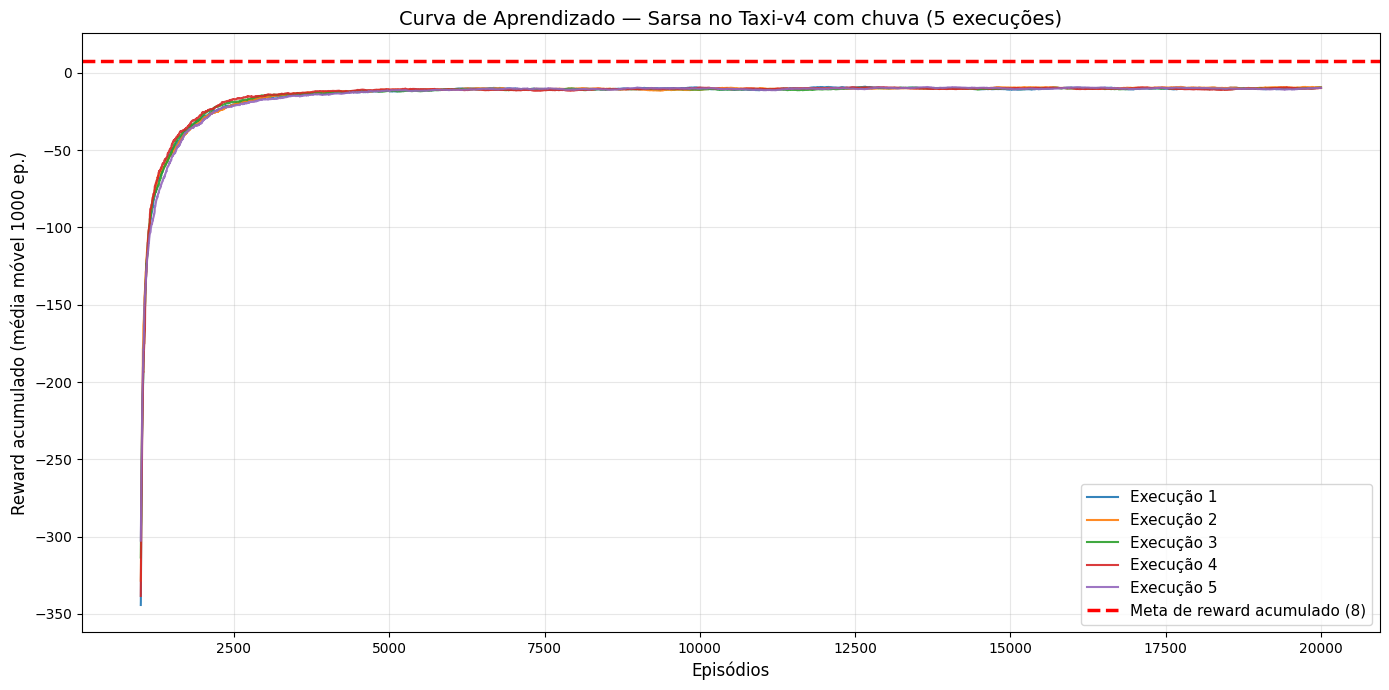

In [6]:
def moving_average(x, window=1000):
    return np.convolve(x, np.ones(window) / window, mode='valid')

plt.figure(figsize=(14, 7))

for i, rewards in enumerate(all_rewards):
    sm = moving_average(np.array(rewards), window=1000)
    plt.plot(np.arange(len(sm)) + 1000, sm,
             linewidth=1.5, alpha=0.9, label=f'Execução {i+1}')

plt.axhline(y=TARGET, color='red', linestyle='--', linewidth=2.5,
            label=f'Meta de reward acumulado ({TARGET})')

plt.xlabel('Episódios', fontsize=12)
plt.ylabel('Reward acumulado (média móvel 1000 ep.)', fontsize=12)
plt.title('Curva de Aprendizado — Sarsa no Taxi-v4 com chuva (5 execuções)', fontsize=14)
plt.legend(fontsize=11, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('results_sarsa_rainy/learning_curve_5runs.jpg', dpi=120)
plt.show()

In [7]:
avaliacao_sarsa_chuva = avaliar('data_sarsa_rainy', 'sarsa', **CHUVA)
avaliacao_sarsa_chuva

,Execução,Timesteps (média),Desvio padrão,Mín,Máx,Reward médio,Penalidades,Não terminou
0,1,26.20,9.82,11.0,62.0,-5.20,0.0,0.0
1,2,29.12,26.39,11.0,200.0,-8.54,0.0,2.0
2,3,26.15,9.63,11.0,62.0,-5.15,0.0,0.0
3,4,26.22,10.02,11.0,58.0,-5.22,0.0,0.0
4,5,26.36,10.64,9.0,66.0,-5.36,0.0,0.0
Média,Média,26.81,13.30,9.0,200.0,-5.89,0.0,0.4


#### Discussão - Resultados do Sarsa com chuva (is_rainy=True, rainy_probability=0.6)

Com os mesmos parâmetros do Q-Learning, o Sarsa foi avaliado no ambiente Taxi-v4 com chuva, em que o táxi possui 60% de probabilidade de se movimentar na direção desejada e 40% de probabilidade de sofrer desvios laterais.

| Execução | Timesteps (média) | Desvio padrão | Mín / Máx | Reward médio | Penalidades | Não terminou |
|---|---|---|---|---|---|---|
| 1 | 26,20 | 9,82 | 11 / 62 | -5,20 | 0 | 0 |
| 2 | 29,12 | 26,39 | 11 / 200 | -8,54 | 0 | 2 |
| 3 | 26,15 | 9,63 | 11 / 62 | -5,15 | 0 | 0 |
| 4 | 26,22 | 10,02 | 11 / 58 | -5,22 | 0 | 0 |
| 5 | 26,36 | 10,64 | 9 / 66 | -5,36 | 0 | 0 |
| **Média** | **26,81** | **13,30** | 9 / 200 | **-5,89** | **0** | **0,4** |

A média do Sarsa (26,81 passos) ficou acima da do Q-learning (25,74), mas quase toda essa diferença vem da execução 2: em 2 dos 100 episódios o táxi ficou preso até o limite de 200 passos. Sem ela, o Sarsa fica em 26,23 passos, cerca de 0,5 passo a mais que o Q-learning. É uma diferença pequena, que não dá para afirmar com só 100 episódios de teste, já que cada episódio com chuva varia bastante (desvio padrão de ~10 passos).

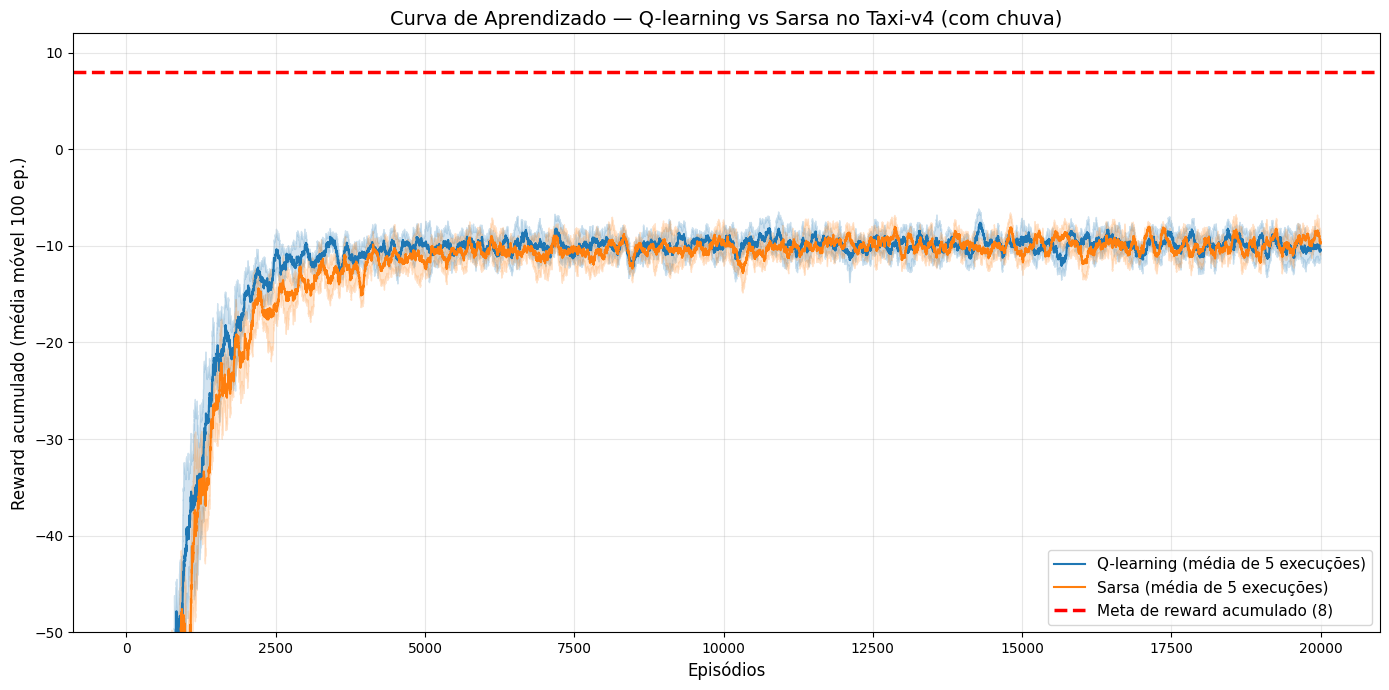

Q-learning | reward >= -20: episódios [1520, 1304, 1620, 1424, 1514] | média 1476 | atingiram: 5/5
Sarsa | reward >= -20: episódios [1835, 1807, 1557, 1580, 1579] | média 1672 | atingiram: 5/5
Q-learning | reward >= -12: episódios [2134, 2029, 2149, 2382, 1987] | média 2136 | atingiram: 5/5
Sarsa | reward >= -12: episódios [2894, 2620, 2611, 2111, 2895] | média 2626 | atingiram: 5/5


In [8]:
EPISODES, TARGET = 20_000, 8
ql_rewards = np.load('results_qlearning_rainy/rewards_qlearning.npy')
sarsa_rewards = np.load('results_sarsa_rainy/rewards_sarsa.npy')

WINDOW = 100

def moving_average(x, window=WINDOW):
    return np.convolve(x, np.ones(window) / window, mode='valid')

def curva_media(rewards_runs):
    curvas = np.array([moving_average(np.array(r)) for r in rewards_runs])
    return curvas.mean(axis=0), curvas.std(axis=0)

x = np.arange(WINDOW, EPISODES + 1)

plt.figure(figsize=(14, 7))
for nome, rewards, cor in [('Q-learning', ql_rewards, 'tab:blue'), 
                           ('Sarsa', sarsa_rewards, 'tab:orange')]:
    media, desvio = curva_media(rewards)
    plt.plot(x, media, color=cor, linewidth=1.5, label=f'{nome} (média de 5 execuções)')
    plt.fill_between(x, media - desvio, media + desvio, color=cor, alpha=0.2)

plt.axhline(y=TARGET, color='red', linestyle='--', linewidth=2.5,
            label=f'Meta de reward acumulado ({TARGET})')

plt.ylim(-50, 12)
plt.xlabel('Episódios', fontsize=12)
plt.ylabel(f'Reward acumulado (média móvel {WINDOW} ep.)', fontsize=12)
plt.title('Curva de Aprendizado — Q-learning vs Sarsa no Taxi-v4 (com chuva)', fontsize=14)
plt.legend(fontsize=11, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('results_comparacao_curvas_chuva.jpg', dpi=120)
plt.show()


def primeiro_episodio(rewards, limiar):
    sm = moving_average(np.array(rewards))
    acima = np.where(sm >= limiar)[0]
    return int(acima[0] + WINDOW) if len(acima) > 0 else None

for limiar in [-20, -12]:
    for nome, rewards in [('Q-learning', ql_rewards),
                          ('Sarsa', sarsa_rewards)]:
        eps = [primeiro_episodio(r, limiar) for r in rewards]
        eps_validos = [ep for ep in eps if ep is not None]
        if eps_validos:
            media = np.mean(eps_validos)
            print(f"{nome} | reward >= {limiar}: "
                  f"episódios {eps} | média {media:.0f} "
                  f"| atingiram: {len(eps_validos)}/{len(eps)}")
        else:
            print(f"{nome} | reward >= {limiar}: "
                  f"Não atingido em nenhuma execução")


#### Discussão — Q-learning vs Sarsa com chuva

Como na chuva o reward nunca fica positivo, usamos outros limiares para medir a velocidade de aprendizado: -20 (o agente começa a acertar o caminho) e -12 (o agente já está perto do seu nível final).

| Algoritmo | Reward ≥ -20 (episódio médio) | Reward ≥ -12 (episódio médio) |
|---|---|---|
| Q-learning | 1476 | 2136 |
| Sarsa | 1672 | 2626 |

O resultado é o mesmo do ambiente sem chuva: **o Q-learning aprende mais rápido**. Ele chegou a -12 cerca de 490 episódios antes do Sarsa. O motivo também é o mesmo: o Q-learning usa sempre o valor da melhor ação seguinte, então a informação sobre bons caminhos se espalha mais rápido pela Q-table.

No resultado final, os dois ficaram próximos. Seria possível esperar que o Sarsa se saísse melhor num ambiente aleatório, já que ele aprende caminhos mais "cautelosos". Mas, no Taxi, a chuva só faz o táxi perder alguns passos. Não existe nenhum lugar perigoso para onde o táxi pode ir diretamente. Por isso, ser cauteloso não traz vantagem.

A linha da meta aparece no gráfico como referência, mas ela não é alcançável com chuva.

### Item 4 — Q-table do ambiente determinístico testada com chuva

In [9]:
item4_ql = avaliar('data_qlearning', 'qlearning', **CHUVA)
item4_sarsa = avaliar('data_sarsa', 'sarsa', **CHUVA)

print("Q-learning treinado SEM chuva, testado COM chuva:")
display(item4_ql)
print("Sarsa treinado SEM chuva, testado COM chuva:")
display(item4_sarsa)

Q-learning treinado SEM chuva, testado COM chuva:


,Execução,Timesteps (média),Desvio padrão,Mín,Máx,Reward médio,Penalidades,Não terminou
0,1,28.31,20.46,11.0,200.0,-7.52,0.0,1.0
1,2,31.60,31.51,10.0,200.0,-11.23,0.0,3.0
2,3,28.11,19.85,10.0,200.0,-7.32,0.0,1.0
3,4,33.33,35.73,11.0,200.0,-13.17,0.0,4.0
4,5,29.35,26.48,9.0,200.0,-8.77,0.0,2.0
Média,Média,30.14,26.81,9.0,200.0,-9.60,0.0,2.2


Sarsa treinado SEM chuva, testado COM chuva:


,Execução,Timesteps (média),Desvio padrão,Mín,Máx,Reward médio,Penalidades,Não terminou
0,1,26.17,9.93,11.0,59.0,-5.17,0.0,0.0
1,2,29.71,26.42,7.0,200.0,-9.13,0.0,2.0
2,3,34.65,39.03,11.0,200.0,-14.70,0.0,5.0
3,4,27.95,19.82,9.0,200.0,-7.16,0.0,1.0
4,5,26.81,10.48,10.0,58.0,-5.81,0.0,0.0
Média,Média,29.06,21.13,7.0,200.0,-8.39,0.0,1.6


#### Discussão — Item 4: a Q-table do ambiente sem chuva funciona com chuva?

Funciona, mas bem pior que a Q-table treinada com chuva:

| Q-table | Timesteps (média) | Desvio padrão | Reward médio | Episódios que não terminaram (em 100) |
|---|---|---|---|---|
| Q-learning treinado sem chuva | 30,14 | 26,81 | -9,60 | 2,2 |
| Sarsa treinado sem chuva | 29,06 | 21,13 | -8,39 | 1,6 |

O problema principal são os episódios que não terminam: em média, cerca de 2 a cada 100 episódios, o táxi ficou preso até o limite de 200 passos. Isso explica o desvio padrão tão alto (21 a 27) e o máximo de 200 passos.

**Por que isso acontece?** No treino sem chuva, o táxi sempre ia para onde queria. Assim, depois de aprender, ele passava quase sempre pelos mesmos caminhos, e os estados fora desses caminhos foram pouco visitados. A Q-table desses estados ficou mal aprendida. Com chuva, o táxi é empurrado justamente para esses estados não conhecidos. Lá, a ação escolhida pode ser ruim, por exemplo andar contra uma parede. No Taxi com chuva, um movimento contra a parede não sofre desvio: o táxi fica no mesmo lugar com 100% de chance, então ele repete a mesma ação para sempre.

O resultado também variou muito entre as execuções: algumas Q-tables nunca ficaram presas (Sarsa 1 e 5), e outras ficaram presas em até 5 episódios. Isso depende de quais estados cada treino visitou por acaso.

### Item 5 — Comparação geral dos agentes

In [10]:
resultados = {
    ('Sem chuva', 'Sem chuva', 'Q-learning'): avaliar('data_qlearning', 'qlearning'),
    ('Sem chuva', 'Sem chuva', 'Sarsa'):      avaliar('data_sarsa', 'sarsa'),
    ('Sem chuva', 'Com chuva', 'Q-learning'): item4_ql,
    ('Sem chuva', 'Com chuva', 'Sarsa'):      item4_sarsa,
    ('Com chuva', 'Com chuva', 'Q-learning'): avaliacao_ql_chuva,
    ('Com chuva', 'Com chuva', 'Sarsa'):      avaliacao_sarsa_chuva,
}

resumo = pd.DataFrame([
    {'Treinado em': t, 'Testado em': a, 'Algoritmo': alg,
     **df.loc['Média', ['Timesteps (média)', 'Desvio padrão', 'Reward médio',
                        'Penalidades', 'Não terminou']].to_dict()}
    for (t, a, alg), df in resultados.items()
])
display(resumo)

,Treinado em,Testado em,Algoritmo,Timesteps (média),Desvio padrão,Reward médio,Penalidades,Não terminou
0,Sem chuva,Sem chuva,Q-learning,13.31,2.87,7.69,0.0,0.0
1,Sem chuva,Sem chuva,Sarsa,13.32,2.86,7.68,0.0,0.0
2,Sem chuva,Com chuva,Q-learning,30.14,26.81,-9.60,0.0,2.2
3,Sem chuva,Com chuva,Sarsa,29.06,21.13,-8.39,0.0,1.6
4,Com chuva,Com chuva,Q-learning,25.74,10.09,-4.74,0.0,0.0
5,Com chuva,Com chuva,Sarsa,26.81,13.30,-5.89,0.0,0.4


#### Discussão — Item 5: comparação entre os ambientes

Todos os agentes foram testados nos mesmos 100 episódios, então os números são os mesmos das seções anteriores.

| Treinado em | Testado em | Algoritmo | Timesteps | Desvio padrão | Reward médio | Não terminou |
|---|---|---|---|---|---|---|
| Sem chuva | Sem chuva | Q-learning | 13,31 | 2,87 | 7,69 | 0 |
| Sem chuva | Sem chuva | Sarsa | 13,32 | 2,86 | 7,68 | 0 |
| Sem chuva | Com chuva | Q-learning | 30,14 | 26,81 | -9,60 | 2,2 |
| Sem chuva | Com chuva | Sarsa | 29,06 | 21,13 | -8,39 | 1,6 |
| Com chuva | Com chuva | Q-learning | 25,74 | 10,09 | -4,74 | 0 |
| Com chuva | Com chuva | Sarsa | 26,81 | 13,30 | -5,89 | 0,4 |

- A chuva quase dobra o número de passos, mesmo para o melhor agente (de 13,31 para 25,74).
- Treinar com chuva vale a pena: o agente usa menos passos e fica preso bem menos. O Q-learning treinado com chuva nunca ficou preso; no Sarsa, só a execução 2 ficou, em 2 episódios.
- Sem chuva, Q-learning e Sarsa terminam praticamente iguais. Com chuva, a diferença entre eles vem quase toda da execução 2 do Sarsa.

#### Conclusão Final - Q-Learning vs Sarsa

Os experimentos realizados no ambiente Taxi-v4 demonstraram que tanto o Q-Learning quanto o Sarsa foram capazes de aprender políticas para realizar a tarefa de transportar passageiros. Entretanto, o desempenho dos algoritmos variou conforme as condições do ambiente.

No ambiente determinístico, o **Q-Learning apresentou maior velocidade de aprendizado**, atingindo os limiares de recompensa 0 e 4 antes do Sarsa. Apesar dessa diferença durante o treinamento, ambos alcançaram o mesmo desempenho final, com reward médio de 8,04 e aproximadamente 12,96 passos por episódio, sem penalidades por ações ilegais.

Já no ambiente não determinístico, configurado com `is_rainy=True` e `rainy_probability=0.6`, os dois algoritmos apresentaram maior dificuldade devido à aleatoriedade dos movimentos. Nenhum deles atingiu os limiares de recompensa 0 e 4 durante o treinamento, e as recompensas médias finais permaneceram negativas devido ao aumento do número de passos necessários para concluir as tarefas.

**Comparação dos resultados finais**

| Ambiente | Algoritmo | Timesteps (média) | Desvio padrão | Reward médio | Penalidades |
|---|---|---:|---:|---:|---:|
| Determinístico | Q-Learning | 12,96 | 2,75 | 8,04 | 0 |
| Determinístico | Sarsa | 12,96 | 2,68 | 8,04 | 0 |
| Chuvoso (0,6) | Q-Learning | 26,03 | 11,55 | −5,07 | 0 |
| Chuvoso (0,6) | Sarsa | 25,49 | 10,05 | −4,49 | 0 |

A tabela evidencia que, no ambiente determinístico, os dois algoritmos alcançaram resultados praticamente idênticos. Já no ambiente chuvoso, o Sarsa apresentou um desempenho ligeiramente superior, necessitando de aproximadamente 0,54 passo a menos por episódio e obtendo um reward médio 0,58 ponto maior que o Q-Learning.

Além disso, observa-se que a introdução da chuva praticamente dobrou o número médio de passos necessários para completar as tarefas, reduzindo significativamente as recompensas acumuladas. Isso demonstra o impacto da aleatoriedade das transições sobre a eficiência dos agentes.

**Comparação da velocidade de aprendizado**

| Ambiente | Algoritmo | Reward ≥ 0 | Reward ≥ 4 |
|---|---|---|---|
| Determinístico | Q-Learning | 1001 | 1279 |
| Determinístico | Sarsa | 1141 | 1480 |
| Chuvoso (0,6) | Q-Learning | Não atingido | Não atingido |
| Chuvoso (0,6) | Sarsa | Não atingido | Não atingido |

No ambiente determinístico, o Q-Learning atingiu o reward 0 aproximadamente 140 episódios antes do Sarsa e o reward 4 cerca de 201 episódios antes. No ambiente chuvoso, nenhum dos algoritmos atingiu esses limiares durante o treinamento, impossibilitando uma comparação direta de velocidade por esse critério.

Portanto, os resultados mostram que **o Q-Learning foi mais rápido no aprendizado no ambiente determinístico, enquanto o Sarsa apresentou uma pequena vantagem no desempenho final do ambiente chuvoso**. Ambos demonstraram capacidade de aprender políticas funcionais, mas a aleatoriedade dos movimentos aumentou o custo das trajetórias e reduziu as recompensas.

Conclui-se que não existe um algoritmo claramente superior em todas as condições analisadas. O desempenho depende das características do ambiente, sendo o Q-Learning mais eficiente em velocidade de aprendizado no cenário determinístico e o Sarsa ligeiramente mais eficiente em número de passos e recompensa média no cenário estocástico. Entretanto, as pequenas diferenças observadas no ambiente chuvoso não são suficientes para estabelecer superioridade estatística.